In [65]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [66]:
import warnings
warnings.filterwarnings('ignore')

In [67]:
data = pd.read_csv(r"C:\Users\nagar\Downloads\Delivery_Logistics.csv")

In [68]:
data.head(3)

,delivery_id,delivery_partner,package_type,vehicle_type,delivery_mode,region,weather_condition,distance_km,package_weight_kg,delivery_time_hours,expected_time_hours,delayed,delivery_status,delivery_rating,delivery_cost
0,250.99,delhivery,automobile parts,bike,same day,west,clear,297.0,46.96,1970-01-01 00:00:00.000000008,1970-01-01 00:00:00.000000008,no,delivered,3,1632.7206
1,250.99,xpressbees,cosmetics,ev van,express,central,cold,89.6,47.39,1970-01-01 00:00:00.000000002,1970-01-01 00:00:00.000000003,no,delivered,5,640.1700
2,250.99,shadowfax,groceries,truck,two day,east,rainy,273.5,26.89,1970-01-01 00:00:00.000000010,1970-01-01 00:00:00.000000016,no,delivered,4,1448.1700


In [69]:
data.drop(['delivery_time_hours','delivery_status'],axis=1,inplace=True)

In [70]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   delivery_id          25000 non-null  float64
 1   delivery_partner     25000 non-null  str    
 2   package_type         25000 non-null  str    
 3   vehicle_type         25000 non-null  str    
 4   delivery_mode        25000 non-null  str    
 5   region               25000 non-null  str    
 6   weather_condition    25000 non-null  str    
 7   distance_km          25000 non-null  float64
 8   package_weight_kg    25000 non-null  float64
 9   expected_time_hours  25000 non-null  str    
 10  delayed              25000 non-null  str    
 11  delivery_rating      25000 non-null  int64  
 12  delivery_cost        25000 non-null  float64
dtypes: float64(4), int64(1), str(8)
memory usage: 2.5 MB


In [71]:
(data.isnull().sum()).sort_values(ascending=False)

delivery_id            0
delivery_partner       0
package_type           0
vehicle_type           0
delivery_mode          0
region                 0
weather_condition      0
distance_km            0
package_weight_kg      0
expected_time_hours    0
delayed                0
delivery_rating        0
delivery_cost          0
dtype: int64

In [72]:
data.duplicated().sum()

np.int64(0)

In [73]:
data['expected_time_hours'] = pd.to_datetime(data['expected_time_hours']).dt.nanosecond 

In [74]:
data['expected_time_hours'].head()

0     8
1     3
2    16
3     8
4    16
Name: expected_time_hours, dtype: int32

### check how much delayed delevery in form of percentage(%).

In [75]:
data['delayed'].value_counts(normalize=True)*100

delayed
no     73.324
yes    26.676
Name: proportion, dtype: float64

### see the charts and understand the data what is work and how it was split.

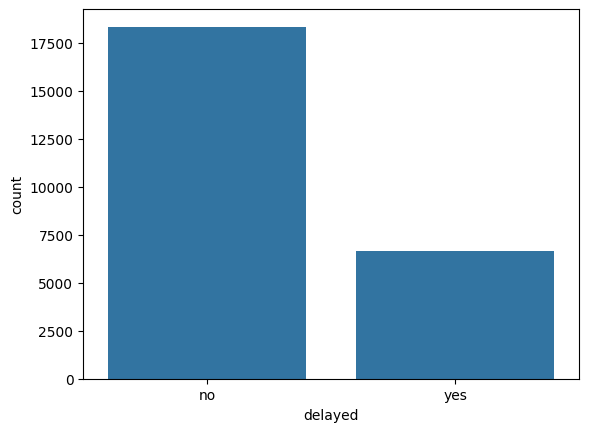

In [76]:
sns.countplot(data,x='delayed')
plt.show()

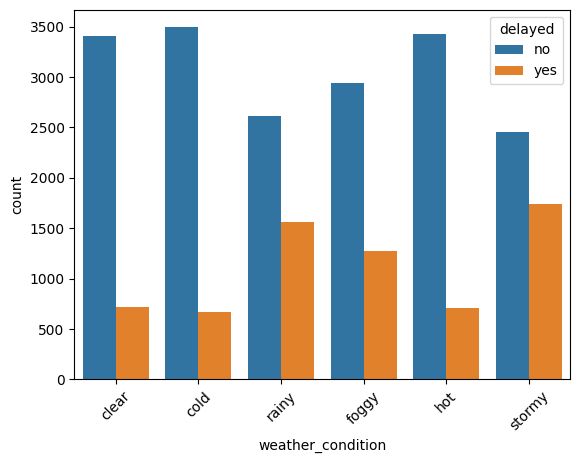

In [77]:
sns.countplot(
    data, x='weather_condition',
    hue='delayed'
)
plt.xticks(rotation=45)
plt.show()

In [78]:
data[['delayed','region']].value_counts()

delayed  region 
no       west       3722
         central    3681
         east       3650
         south      3644
         north      3634
yes      central    1379
         west       1373
         south      1333
         north      1315
         east       1269
Name: count, dtype: int64

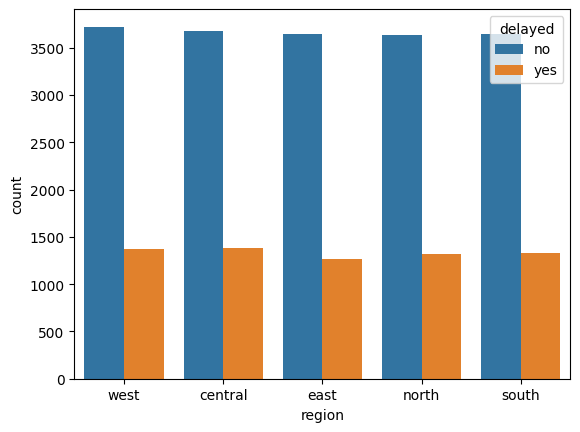

In [79]:
sns.countplot(data,x='region',hue='delayed')
plt.show()

In [80]:
data[['delayed','vehicle_type']].value_counts()

delayed  vehicle_type
no       ev bike         3103
         scooter         3083
         van             3066
         bike            3035
         truck           3024
         ev van          3020
yes      bike            1125
         truck           1121
         van             1121
         ev bike         1115
         ev van          1096
         scooter         1091
Name: count, dtype: int64

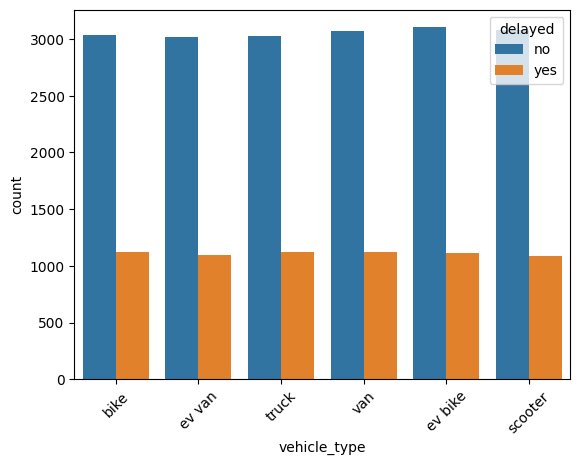

In [81]:
sns.countplot(data,x='vehicle_type',hue='delayed')
plt.xticks(rotation=45)
plt.show()

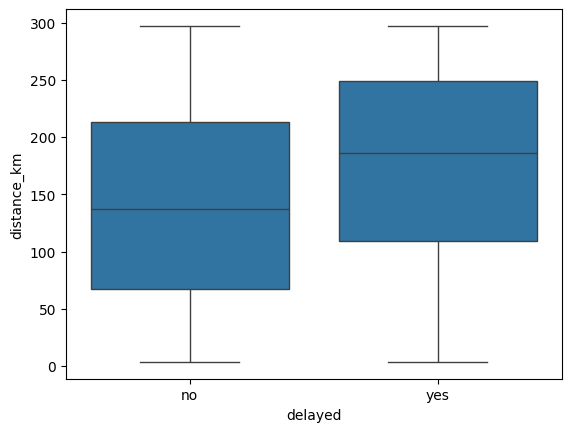

In [82]:

sns.boxplot(data,x='delayed',y='distance_km')
plt.show()

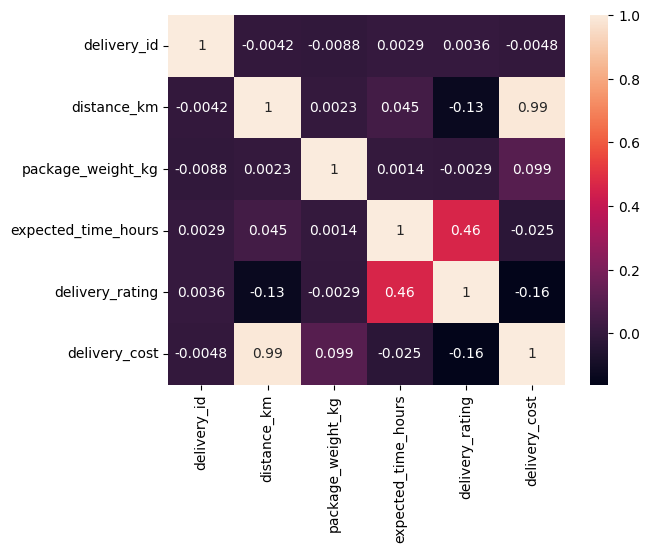

In [83]:
num_data = data.select_dtypes(include=np.number)

sns.heatmap(num_data.corr(),annot=True)

plt.show()

In [84]:
data.drop('delivery_id',axis=1, inplace=True)

### split data into two variables

In [85]:
x = data.drop('delayed', axis=1,)
y = data['delayed']

In [86]:
from sklearn.model_selection import train_test_split

### split in training and testing model 

In [87]:
X_train,X_test,Y_train,Y_test = train_test_split(x,y,train_size=0.8,random_state=42,stratify=y)

In [88]:
num_col = x.select_dtypes(include=np.number).columns
cat_col = x.select_dtypes(include=['object','category']).columns

In [89]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline,Pipeline

In [90]:
from sklearn.compose import ColumnTransformer 
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import LabelEncoder

### make pipline connects all preprocessing steps and the model into a single object

In [91]:
lr  = LabelEncoder()

y = lr.fit_transform(y)

In [92]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            Pipeline([
                ('imputer',SimpleImputer(strategy='median')),
                ('scaler',StandardScaler())
            ]),
            num_col
        ),
        (
            'cat',
            Pipeline([
                ('imputer', SimpleImputer(strategy='most_frequent')),
                ('encoder',OneHotEncoder(handle_unknown='ignore'))

            ]),
            cat_col
        )
    ]
)

### use model - logisticRegression - our output in category form 

In [93]:
from sklearn.linear_model import LogisticRegression


In [94]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix
from sklearn.model_selection import cross_val_score

In [95]:
Pipe_lr  = Pipeline([
    ('preprocessor',preprocessor),
    ('model',LogisticRegression(max_iter=1000))
])

Pipe_lr.fit(X_train,Y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [96]:
Y_pred = Pipe_lr.predict(X_test)

In [97]:
print("Accuracy :",accuracy_score(Y_test,Y_pred))
print("Precision:",precision_score(Y_test,Y_pred,pos_label='yes'))
print("Recall   :",recall_score(Y_test,Y_pred,pos_label='yes'))
print("F1 Score :",f1_score(Y_test,Y_pred,pos_label='yes'))

Accuracy : 0.9742
Precision: 0.9433406916850625
Recall   : 0.9610194902548725
F1 Score : 0.9520980319346454


In [98]:
print('classification_report : ')
print(classification_report(Y_test,Y_pred))


classification_report : 
              precision    recall  f1-score   support

          no       0.99      0.98      0.98      3666
         yes       0.94      0.96      0.95      1334

    accuracy                           0.97      5000
   macro avg       0.96      0.97      0.97      5000
weighted avg       0.97      0.97      0.97      5000



### confusion matrix with heatmap to better understanding

confusion_matrix : 
[[3589   77]
 [  52 1282]]


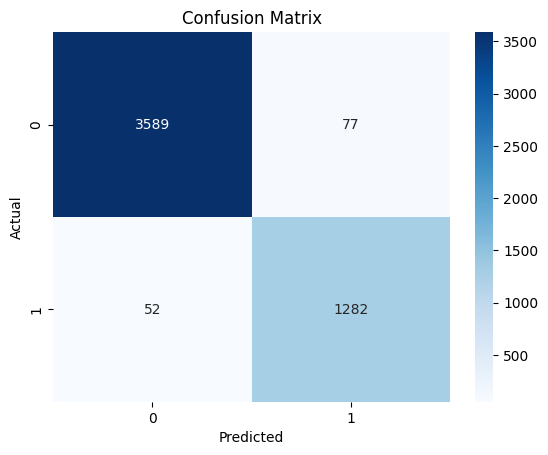

In [99]:
print('confusion_matrix : ')
print(confusion_matrix(Y_test,Y_pred))

cm = confusion_matrix(Y_test, Y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

plt.show()

### Cross Validation score

In [100]:
from sklearn.model_selection import cross_val_score

In [101]:
scores = cross_val_score(Pipe_lr,x,y,cv=5,scoring='f1')

print(scores.mean())

0.9559095090093599


compare models and check accuracy_score or cross_validation_score 

In [102]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

In [103]:
models = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'KNN': KNeighborsClassifier()
}

In [ ]:
results = []

for name, models in models.items():

    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('model', models)
    ])

    pipe.fit(X_train, Y_train)

    y_pred = pipe.predict(X_test)

    results.append([
        name,
        accuracy_score(Y_test, y_pred),
        cross_val_score(
            pipe,
            x,
            y,
            cv=5,
            scoring='accuracy'
        ).mean()
    ])

result_df = pd.DataFrame(
    results,
    columns=['Model', 'Accuracy', 'CV Score']
)

print(result_df.sort_values('CV Score', ascending=False))

                 Model  Accuracy  CV Score
0  Logistic Regression    0.9742   0.97620
2        Random Forest    0.9746   0.97500
1        Decision Tree    0.9646   0.96832
3                  KNN    0.9676   0.96796


give details and check what is out put delevery delay = "Yes" or "No"

In [105]:
new_data = pd.DataFrame({
    'delivery_partner': ['Partner_A'],
    'distance_km': [12.5],
    'weather_condition': ['Rainy'],
    'traffic_level': ['High'],
    'delivery_rating': [4.5],
    'delivery_cost': [120],
    'package_type': ['Electronics'],
    'region': ['Urban'],
    'vehicle_type': ['Bike'],
    'expected_time_hours': [2],
    'delivery_mode': ['Express'],
    'package_weight_kg': [5]
})

prediction = Pipe_lr.predict(new_data)

print(prediction)

['no']


we see first 20 how our model prediction accurate 

In [106]:
comparison = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': y_pred
})

print(comparison.head(20))

      Actual Predicted
8150      no        no
9504     yes       yes
17921     no        no
6370      no        no
2560     yes       yes
14243     no        no
23754    yes       yes
12144    yes       yes
17642     no        no
23309     no        no
10350    yes       yes
14810     no        no
4118     yes       yes
150       no        no
15211     no        no
23201     no        no
7750      no        no
21983     no        no
18172     no        no
22213    yes       yes


we see where our model prediction wrong and check it 


In [107]:
comparison = pd.DataFrame({
    'Actual': Y_test,
    'Predicted': y_pred
})

wrong_predictions = comparison[
    comparison['Actual'] != comparison['Predicted']
]

print(wrong_predictions.head())

      Actual Predicted
10999     no       yes
12653    yes        no
8365      no       yes
17892    yes        no
16832    yes        no
